# Track B — Segmentation: Santander Product Portfolio (Kaggle)

**Track:** B — Representation Learning (Autoencoder) vs K-Means baseline  
**Platform:** Kaggle Notebook  
**Data source:** `santander-product-recommendation` competition (see step 2 below)  
**Methods:** K-Means (continuous) · K-Means (full sparse) · AE+KMeans (latent 8/16/32)  
**Output:** `/kaggle/working/comparison_board_track_b.csv`

> **Recommended flag:** AE is the EDA prior for this track (sparse binary products).  
> Running K-Means baselines to let the rubric confirm or falsify that prior.

> 💡 **Tip:** Enable GPU (T4 x2) in Notebook Settings → Accelerator for ~3x faster AE training.

In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score,
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
K_RANGE = range(3, 9)
print('=== IMPORTS OK — Track B: Santander (Kaggle) ===')

=== IMPORTS OK — Track B: Santander (Kaggle) ===


## 1. Data Loading

In [2]:
# ── Kaggle data path ─────────────────────────────────────────────────────
# Kaggle serves competition data as  train_ver2.csv.zip  (pandas reads it directly).
# Fallback chain: plain CSV → .zip → any zip in folder

# Kaggle mounts inputs under different prefixes depending on source type:
#   competitions → /kaggle/input/competitions/<slug>/
#   datasets     → /kaggle/input/datasets/<user>/<slug>/
# Try both known locations in order.

candidates = [
    # xhk300 dataset — plain CSV, no unzip needed  ← confirmed working
    Path("/kaggle/input/datasets/xhk300/santander-product-recommendation-extract/train_ver2.csv"),
    # competition data (requires rule acceptance)
    Path("/kaggle/input/competitions/santander-product-recommendation/train_ver2.csv.zip"),
    Path("/kaggle/input/competitions/santander-product-recommendation/train_ver2.csv"),
    # legacy flat path (older Kaggle kernels)
    Path("/kaggle/input/santander-product-recommendation/train_ver2.csv.zip"),
    Path("/kaggle/input/santander-product-recommendation/train_ver2.csv"),
]

RAW_PATH = next((p for p in candidates if p.exists()), None)
assert RAW_PATH, (
    "No Santander data found. Run this to see what is mounted:\n"
    "  import os\n"
    "  for d,_,fs in os.walk('/kaggle/input'):\n"
    "      for f in fs: print(os.path.join(d,f))"
)
print(f"Data file : {RAW_PATH}")
print(f"Size      : {RAW_PATH.stat().st_size / 1e6:.0f} MB")

TARGET_DATE = "2016-05-28"
PRODUCT_COLS_RAW = [
    "ind_cco_fin_ult1","ind_cno_fin_ult1","ind_ctju_fin_ult1","ind_ctop_fin_ult1",
    "ind_ctpp_fin_ult1","ind_deco_fin_ult1","ind_dela_fin_ult1","ind_ecue_fin_ult1",
    "ind_fond_fin_ult1","ind_hip_fin_ult1","ind_plan_fin_ult1","ind_pres_fin_ult1",
    "ind_reca_fin_ult1","ind_tjcr_fin_ult1","ind_valo_fin_ult1","ind_nomina_ult1",
    "ind_nom_pens_ult1","ind_recibo_ult1",
]
PRODUCT_NAMES = {
    "ind_cco_fin_ult1":"has_current_acct","ind_cno_fin_ult1":"has_payroll_acct",
    "ind_ctju_fin_ult1":"has_junior_acct","ind_ctop_fin_ult1":"has_particular_acct",
    "ind_ctpp_fin_ult1":"has_particular_plus","ind_deco_fin_ult1":"has_short_deposit",
    "ind_dela_fin_ult1":"has_long_deposit","ind_ecue_fin_ult1":"has_e_account",
    "ind_fond_fin_ult1":"has_funds","ind_hip_fin_ult1":"has_mortgage",
    "ind_plan_fin_ult1":"has_pensions","ind_pres_fin_ult1":"has_loans",
    "ind_reca_fin_ult1":"has_taxes","ind_tjcr_fin_ult1":"has_credit_card",
    "ind_valo_fin_ult1":"has_securities","ind_nomina_ult1":"has_payroll",
    "ind_nom_pens_ult1":"has_pension_nom","ind_recibo_ult1":"has_direct_debit",
}
KEEP_COLS = ["ncodpers","age","antiguedad","renta","ind_actividad_cliente",
             "sexo","fecha_dato"] + PRODUCT_COLS_RAW
dtypes_b  = {c: "float32" for c in PRODUCT_COLS_RAW}
dtypes_b.update({"ncodpers":"int32","renta":"float32","ind_actividad_cliente":"float32"})

print("Loading chunked snapshot (may take ~1-2 min for 13.6M rows)...")
chunks = []
for chunk in pd.read_csv(RAW_PATH, usecols=KEEP_COLS, dtype=dtypes_b,
                         chunksize=500_000, low_memory=False):
    filtered = chunk[chunk["fecha_dato"] == TARGET_DATE]
    if len(filtered):
        chunks.append(filtered)
df_raw = pd.concat(chunks, ignore_index=True)
print(f"  Snapshot {TARGET_DATE}: {df_raw.shape}")

df_raw.rename(columns={"ncodpers":"customer_id","antiguedad":"seniority_months",
                       "renta":"gross_income","ind_actividad_cliente":"activity_index",
                       **PRODUCT_NAMES}, inplace=True)

df_raw["age"]              = pd.to_numeric(df_raw["age"],              errors="coerce")
df_raw["seniority_months"] = pd.to_numeric(df_raw["seniority_months"], errors="coerce")
df_raw["is_female"]        = (df_raw["sexo"] == "V").astype(int)

for col in ["age","seniority_months","gross_income","activity_index"]:
    if col in df_raw.columns:
        df_raw[col] = df_raw[col].fillna(df_raw[col].median())

prod_cols = [c for c in df_raw.columns if c.startswith("has_")]
df_raw[prod_cols] = df_raw[prod_cols].fillna(0)
df_raw["total_products"] = df_raw[prod_cols].sum(axis=1)
df_raw.drop(columns=[c for c in ["sexo","fecha_dato"] if c in df_raw.columns], inplace=True)

df_interp = df_raw.copy()
df_model  = df_raw.copy()

cont_cols = ["age","seniority_months","gross_income","total_products","activity_index"]
cont_cols = [c for c in cont_cols if c in df_model.columns]
scaler    = StandardScaler()
df_model[cont_cols] = scaler.fit_transform(df_model[cont_cols])
print(f"  Inline FE complete: {df_model.shape}")

# Sample to 100k for training speed (full 931k is available but slow on CPU)
SAMPLE_B = 100_000
if len(df_model) > SAMPLE_B:
    sample_b_idx = np.random.choice(len(df_model), SAMPLE_B, replace=False)
    df_model_s  = df_model.iloc[sample_b_idx].reset_index(drop=True)
    df_interp_s = df_interp.iloc[sample_b_idx].reset_index(drop=True)
    print(f"Sampled to {SAMPLE_B:,} rows for training (out of {len(df_model):,}).")
else:
    df_model_s  = df_model
    df_interp_s = df_interp

print(f"Working dataset: {df_model_s.shape}")

Data file : /kaggle/input/datasets/xhk300/santander-product-recommendation-extract/train_ver2.csv
Size      : 2293 MB
Loading chunked snapshot (may take ~1-2 min for 13.6M rows)...
  Snapshot 2016-05-28: (931453, 25)
  Inline FE complete: (931453, 25)
Sampled to 100,000 rows for training (out of 931,453).
Working dataset: (100000, 25)


In [3]:
ID_COL_B = "customer_id" if "customer_id" in df_model_s.columns else df_model_s.columns[0]

PROD_COLS = [c for c in df_model_s.columns if c.startswith("has_")]
CONT_COLS = [c for c in ["age","seniority_months","gross_income","total_products",
                          "activity_index","is_female"]
             if c in df_model_s.columns]
ALL_FEAT  = CONT_COLS + PROD_COLS
ALL_FEAT  = [c for c in ALL_FEAT if c in df_model_s.columns]

X_full_b  = df_model_s[ALL_FEAT].fillna(0).values.astype(np.float32)
X_cont_b  = df_model_s[CONT_COLS].fillna(0).values.astype(np.float32)

SIL_N_B   = 10_000
sil_b_idx = np.random.choice(len(X_full_b), min(SIL_N_B, len(X_full_b)), replace=False)

print(f"Full feature matrix  : {X_full_b.shape}")
print(f"Continuous only      : {X_cont_b.shape}")
print(f"Product columns ({len(PROD_COLS)}) : {PROD_COLS}")

Full feature matrix  : (100000, 24)
Continuous only      : (100000, 6)
Product columns (18) : ['has_current_acct', 'has_payroll_acct', 'has_junior_acct', 'has_particular_acct', 'has_particular_plus', 'has_short_deposit', 'has_long_deposit', 'has_e_account', 'has_funds', 'has_mortgage', 'has_pensions', 'has_loans', 'has_taxes', 'has_credit_card', 'has_securities', 'has_payroll', 'has_pension_nom', 'has_direct_debit']


## 2. K-Means Baselines (Continuous & Full Matrix)

The full matrix baseline is expected to **underperform** on sparse binaries —
this is the hypothesis the AE track exists to test.

=== BASELINE 1: K-Means on Continuous Features ===
  k=3 | sil=0.363 | DB=0.989 | CH=5278
  k=4 | sil=0.395 | DB=1.007 | CH=5820
  k=5 | sil=0.394 | DB=1.004 | CH=5820
  k=6 | sil=0.380 | DB=1.061 | CH=5746
  k=7 | sil=0.339 | DB=1.135 | CH=5363
  k=8 | sil=0.339 | DB=1.000 | CH=4702

=== BASELINE 2: K-Means on Full Product+Continuous Matrix ===
  k=3 | sil=0.350 | DB=1.273 | CH=4069
  k=4 | sil=0.319 | DB=1.194 | CH=4121
  k=5 | sil=0.319 | DB=1.194 | CH=4121
  k=6 | sil=0.313 | DB=1.342 | CH=3860
  k=7 | sil=0.291 | DB=1.347 | CH=3543
  k=8 | sil=0.281 | DB=1.371 | CH=3197


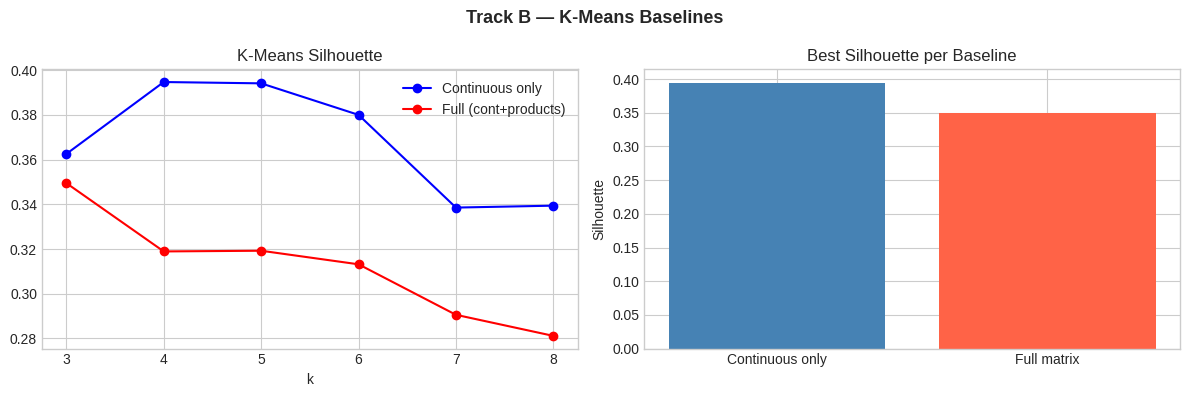

Best k (continuous): 4 | Best k (full): 3
NOTE: Sparse product matrix typically hurts K-Means (curse of dimensionality).


In [4]:
print("=== BASELINE 1: K-Means on Continuous Features ===")
km_cont_results = {}
sil_cont = []

for k in K_RANGE:
    km  = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    lbl = km.fit_predict(X_cont_b)
    sil = silhouette_score(X_cont_b[sil_b_idx], lbl[sil_b_idx])
    db  = davies_bouldin_score(X_cont_b[sil_b_idx], lbl[sil_b_idx])
    ch  = calinski_harabasz_score(X_cont_b[sil_b_idx], lbl[sil_b_idx])
    km_cont_results[k] = dict(labels=lbl, sil=sil, db=db, ch=ch)
    sil_cont.append(sil)
    print(f"  k={k} | sil={sil:.3f} | DB={db:.3f} | CH={ch:.0f}")

best_k_cont = list(K_RANGE)[int(np.argmax(sil_cont))]

print("\n=== BASELINE 2: K-Means on Full Product+Continuous Matrix ===")
km_full_results = {}
sil_full = []

for k in K_RANGE:
    km  = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    lbl = km.fit_predict(X_full_b)
    sil = silhouette_score(X_full_b[sil_b_idx], lbl[sil_b_idx])
    db  = davies_bouldin_score(X_full_b[sil_b_idx], lbl[sil_b_idx])
    ch  = calinski_harabasz_score(X_full_b[sil_b_idx], lbl[sil_b_idx])
    km_full_results[k] = dict(labels=lbl, sil=sil, db=db, ch=ch)
    sil_full.append(sil)
    print(f"  k={k} | sil={sil:.3f} | DB={db:.3f} | CH={ch:.0f}")

best_k_full = list(K_RANGE)[int(np.argmax(sil_full))]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_RANGE), sil_cont, "b-o", label="Continuous only")
axes[0].plot(list(K_RANGE), sil_full, "r-o", label="Full (cont+products)")
axes[0].set_title("K-Means Silhouette"); axes[0].set_xlabel("k"); axes[0].legend()
axes[1].bar(["Continuous only", "Full matrix"],
            [max(sil_cont), max(sil_full)], color=["steelblue","tomato"])
axes[1].set_title("Best Silhouette per Baseline"); axes[1].set_ylabel("Silhouette")
plt.suptitle("Track B — K-Means Baselines", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Best k (continuous): {best_k_cont} | Best k (full): {best_k_full}")
print("NOTE: Sparse product matrix typically hurts K-Means (curse of dimensionality).")

## 3. Autoencoder + K-Means on Latent Space

Latent dims swept: **8, 16, 32**. Champion chosen by silhouette + product profile distinctness.

💡 Enable GPU in Notebook Settings → Accelerator → T4 GPU for ~3x faster training.

PyTorch 2.11.0+cu128 | device: cuda

--- AE Track B | latent_dim=8 ---
  epoch  20/80 | loss 0.00292
  epoch  40/80 | loss 0.00184
  epoch  60/80 | loss 0.00166
  epoch  80/80 | loss 0.00151
  k=3 on z | sil=0.512 | DB=0.891 | CH=90835

--- AE Track B | latent_dim=16 ---
  epoch  20/80 | loss 0.00067
  epoch  40/80 | loss 0.00031
  epoch  60/80 | loss 0.00033
  epoch  80/80 | loss 0.00020
  k=3 on z | sil=0.353 | DB=1.248 | CH=47550

--- AE Track B | latent_dim=32 ---
  epoch  20/80 | loss 0.00018
  epoch  40/80 | loss 0.00015
  epoch  60/80 | loss 0.00008
  epoch  80/80 | loss 0.00012
  k=3 on z | sil=0.283 | DB=1.539 | CH=28150


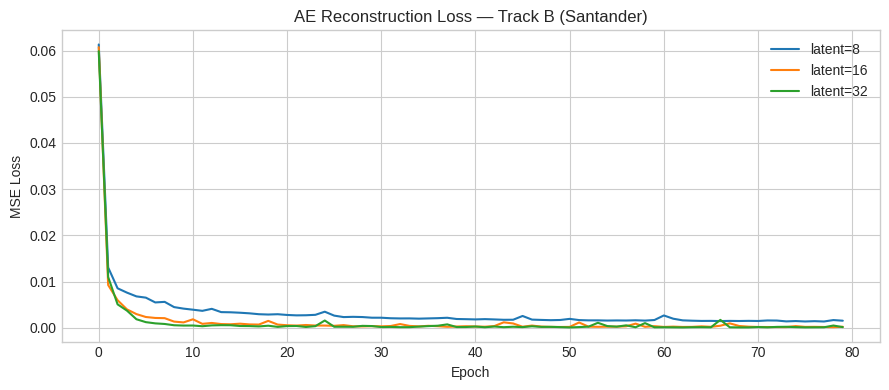


Best AE latent_dim : 8 | sil=0.512
Best K-Means (cont): sil=0.395
Best K-Means (full): sil=0.350


In [5]:
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_OK_B = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"PyTorch {torch.__version__} | device: {device}")
except ImportError:
    TORCH_OK_B = False
    print("PyTorch not installed — AE track skipped.")

if TORCH_OK_B:
    class AETabular(nn.Module):
        def __init__(self, n_feat, lat=16):
            super().__init__()
            self.enc = nn.Sequential(
                nn.Linear(n_feat, 128), nn.ReLU(),
                nn.Linear(128, 64),     nn.ReLU(),
                nn.Linear(64, lat)
            )
            self.dec = nn.Sequential(
                nn.Linear(lat, 64),     nn.ReLU(),
                nn.Linear(64, 128),     nn.ReLU(),
                nn.Linear(128, n_feat)
            )
        def forward(self, x):
            z = self.enc(x)
            return self.dec(z), z

    def fit_ae_b(X_np, lat=16, epochs=80, batch_sz=512):
        Xt   = torch.tensor(X_np, dtype=torch.float32).to(device)
        m    = AETabular(X_np.shape[1], lat).to(device)
        opt  = torch.optim.Adam(m.parameters(), lr=1e-3)
        crit = nn.MSELoss()
        ld   = DataLoader(TensorDataset(Xt), batch_size=batch_sz, shuffle=True)
        losses = []
        for ep in range(epochs):
            m.train(); ep_l = 0
            for (b,) in ld:
                opt.zero_grad()
                loss = crit(m(b)[0], b)
                loss.backward(); opt.step()
                ep_l += loss.item()
            losses.append(ep_l / len(ld))
            if (ep + 1) % 20 == 0:
                print(f"  epoch {ep+1:3d}/{epochs} | loss {losses[-1]:.5f}")
        m.eval()
        with torch.no_grad():
            Xt_all = torch.tensor(X_np, dtype=torch.float32).to(device)
            _, z   = m(Xt_all)
        return z.cpu().numpy(), losses

    ae_b_results = {}
    for lat in [8, 16, 32]:
        print(f"\n--- AE Track B | latent_dim={lat} ---")
        torch.manual_seed(RANDOM_STATE)
        z, losses = fit_ae_b(X_full_b, lat=lat, epochs=80)
        km_z = KMeans(n_clusters=best_k_full, n_init=20, random_state=RANDOM_STATE)
        lbl  = km_z.fit_predict(z)
        sil  = silhouette_score(z, lbl)
        db   = davies_bouldin_score(z, lbl)
        ch   = calinski_harabasz_score(z, lbl)
        ae_b_results[lat] = dict(z=z, labels=lbl, losses=losses, sil=sil, db=db, ch=ch)
        print(f"  k={best_k_full} on z | sil={sil:.3f} | DB={db:.3f} | CH={ch:.0f}")

    fig, ax = plt.subplots(figsize=(9, 4))
    for lat, r in ae_b_results.items():
        ax.plot(r["losses"], label=f"latent={lat}")
    ax.set_title("AE Reconstruction Loss — Track B (Santander)")
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE Loss")
    ax.legend(); plt.tight_layout(); plt.show()

    best_ae_lat = max(ae_b_results, key=lambda l: ae_b_results[l]["sil"])
    print(f"\nBest AE latent_dim : {best_ae_lat} | sil={ae_b_results[best_ae_lat]['sil']:.3f}")
    print(f"Best K-Means (cont): sil={max(sil_cont):.3f}")
    print(f"Best K-Means (full): sil={max(sil_full):.3f}")
else:
    ae_b_results = {}
    best_ae_lat  = None

## 4. Product Penetration Profiles per Cluster

Core Track B evaluation: do segments separate on **which products customers hold**?

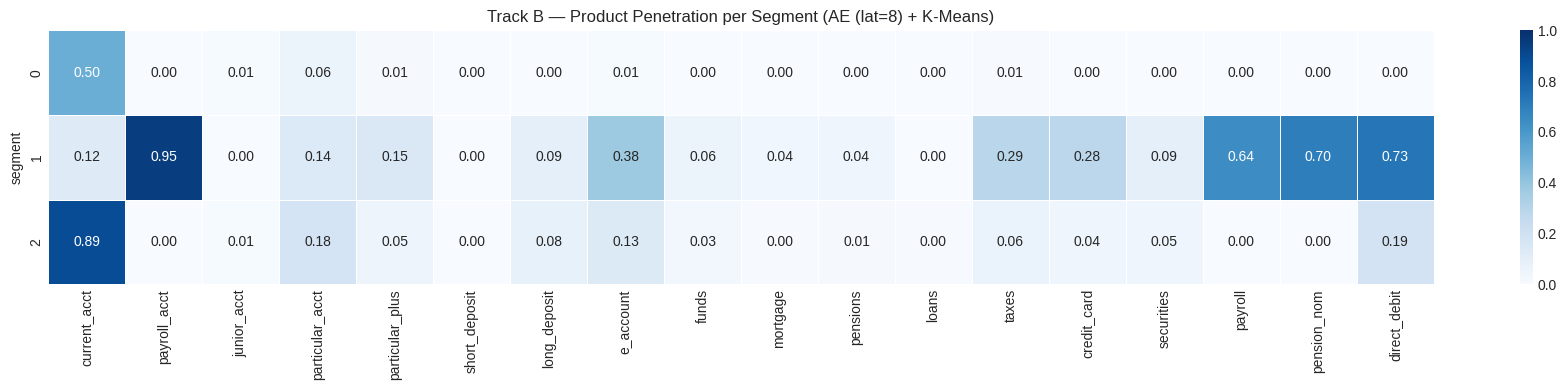

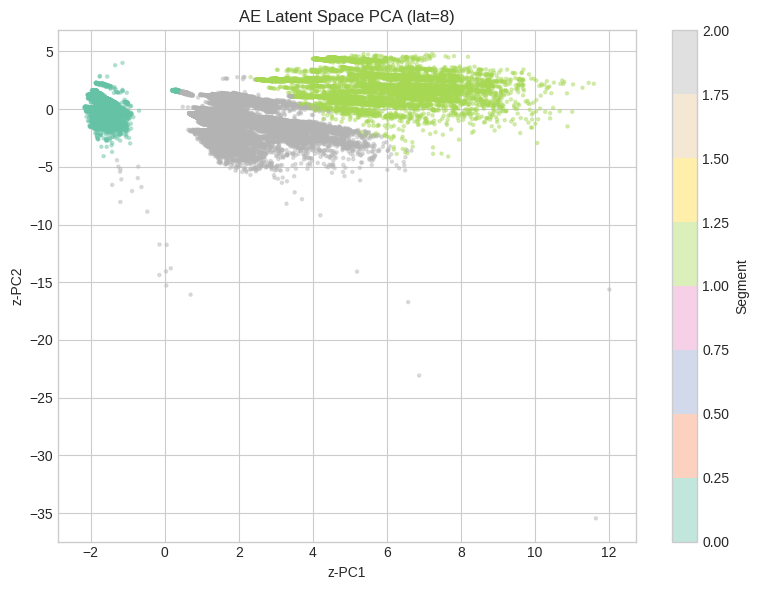

In [6]:
k_show = best_k_full

if TORCH_OK_B and ae_b_results:
    best_lbl_b  = ae_b_results[best_ae_lat]["labels"]
    method_show = f"AE (lat={best_ae_lat}) + K-Means"
else:
    best_lbl_b  = km_full_results[k_show]["labels"]
    method_show = f"K-Means full (k={k_show})"

profile_b = df_interp_s.copy().reset_index(drop=True)
n_show    = min(len(best_lbl_b), len(profile_b))
profile_b = profile_b.iloc[:n_show].copy()
profile_b["segment"] = best_lbl_b[:n_show]

prod_profile = profile_b.groupby("segment")[PROD_COLS].mean().round(3)
prod_profile.columns = [c.replace("has_","") for c in prod_profile.columns]

fig, ax = plt.subplots(figsize=(max(12, len(PROD_COLS)), k_show + 1))
sns.heatmap(prod_profile, annot=True, fmt=".2f", cmap="Blues",
            linewidths=0.5, ax=ax, vmin=0, vmax=1)
ax.set_title(f"Track B — Product Penetration per Segment ({method_show})")
plt.tight_layout(); plt.show()

if TORCH_OK_B and ae_b_results:
    z_best = ae_b_results[best_ae_lat]["z"]
    pca_b  = PCA(n_components=2, random_state=RANDOM_STATE)
    z_pca  = pca_b.fit_transform(z_best)
    fig, ax = plt.subplots(figsize=(8, 6))
    sc = ax.scatter(z_pca[:,0], z_pca[:,1], c=best_lbl_b[:n_show],
                    cmap="Set2", alpha=0.4, s=5)
    ax.set_title(f"AE Latent Space PCA (lat={best_ae_lat})")
    ax.set_xlabel("z-PC1"); ax.set_ylabel("z-PC2")
    plt.colorbar(sc, ax=ax, label="Segment")
    plt.tight_layout(); plt.show()

## 5. Stability Analysis

In [7]:
N_SEEDS_B = 10
ari_b     = []
k_stab_b  = best_k_full
X_stab_b  = X_full_b[:20_000]
base_b    = KMeans(n_clusters=k_stab_b, n_init=10, random_state=0).fit_predict(X_stab_b)

for seed in range(1, N_SEEDS_B + 1):
    lbl_s = KMeans(n_clusters=k_stab_b, n_init=5, random_state=seed).fit_predict(X_stab_b)
    ari_b.append(adjusted_rand_score(base_b, lbl_s))

mean_b = float(np.mean(ari_b))
print(f"K-Means (full) k={k_stab_b} | ARI={mean_b:.3f} +/- {np.std(ari_b):.3f}")

if TORCH_OK_B and ae_b_results:
    ari_ae  = []
    z_sub   = ae_b_results[best_ae_lat]["z"][:20_000]
    base_ae = KMeans(n_clusters=best_k_full, n_init=10, random_state=0).fit_predict(z_sub)
    for seed in range(1, N_SEEDS_B + 1):
        lbl_ae = KMeans(n_clusters=best_k_full, n_init=5, random_state=seed).fit_predict(z_sub)
        ari_ae.append(adjusted_rand_score(base_ae, lbl_ae))
    mean_ae = float(np.mean(ari_ae))
    print(f"AE+KMeans lat={best_ae_lat} k={best_k_full} | ARI={mean_ae:.3f} +/- {np.std(ari_ae):.3f}")
else:
    ari_ae = []; mean_ae = None

K-Means (full) k=3 | ARI=0.977 +/- 0.045
AE+KMeans lat=8 k=3 | ARI=1.000 +/- 0.000


## 6. Comparison Board

In [8]:
rows_b = []

for k, r in km_cont_results.items():
    rows_b.append(dict(run_id=f"b_kmeans_cont_k{k}", track="santander",
                       method="kmeans_continuous", k=k, latent_dim="-",
                       silhouette=round(r["sil"],4), db_index=round(r["db"],4),
                       ch_index=round(r["ch"],0), stability_ari=None, recommended=False))

for k, r in km_full_results.items():
    rows_b.append(dict(run_id=f"b_kmeans_full_k{k}", track="santander",
                       method="kmeans_full", k=k, latent_dim="-",
                       silhouette=round(r["sil"],4), db_index=round(r["db"],4),
                       ch_index=round(r["ch"],0),
                       stability_ari=round(mean_b,3) if k==k_stab_b else None,
                       recommended=False))

for lat, r in ae_b_results.items():
    rows_b.append(dict(run_id=f"b_ae_lat{lat}_k{best_k_full}", track="santander",
                       method="ae_kmeans", k=best_k_full, latent_dim=lat,
                       silhouette=round(r["sil"],4), db_index=round(r["db"],4),
                       ch_index=round(r["ch"],0),
                       stability_ari=round(mean_ae,3) if lat==best_ae_lat and mean_ae else None,
                       recommended=(lat==best_ae_lat)))

board_b = (pd.DataFrame(rows_b)
             .sort_values("silhouette", ascending=False)
             .reset_index(drop=True))

out_path = Path("/kaggle/working/comparison_board_track_b.csv")
board_b.to_csv(out_path, index=False)
print(f"Saved: {out_path}")
display(board_b)

Saved: /kaggle/working/comparison_board_track_b.csv


,run_id,track,method,k,latent_dim,silhouette,db_index,ch_index,stability_ari,recommended
0,b_ae_lat8_k3,santander,ae_kmeans,3,8,0.5118,0.8905,90835.0,1.000,True
1,b_kmeans_cont_k4,santander,kmeans_continuous,4,-,0.3948,1.0066,5820.0,NaN,False
2,b_kmeans_cont_k5,santander,kmeans_continuous,5,-,0.3942,1.0041,5820.0,NaN,False
3,b_kmeans_cont_k6,santander,kmeans_continuous,6,-,0.3800,1.0607,5746.0,NaN,False
4,b_kmeans_cont_k3,santander,kmeans_continuous,3,-,0.3626,0.9894,5278.0,NaN,False
5,b_ae_lat16_k3,santander,ae_kmeans,3,16,0.3531,1.2476,47550.0,NaN,False
6,b_kmeans_full_k3,santander,kmeans_full,3,-,0.3495,1.2728,4069.0,0.977,False
7,b_kmeans_cont_k8,santander,kmeans_continuous,8,-,0.3394,0.9997,4702.0,NaN,False
8,b_kmeans_cont_k7,santander,kmeans_continuous,7,-,0.3385,1.1354,5363.0,NaN,False
9,b_kmeans_full_k5,santander,kmeans_full,5,-,0.3192,1.1941,4121.0,NaN,False


## 7. Summary

In [9]:
best_b = board_b.iloc[0]
print("=" * 60)
print("TRACK B — SEGMENTATION COMPLETE")
print("=" * 60)
print(f"  Best run   : {best_b['run_id']}")
print(f"  Method     : {best_b['method']}")
print(f"  k          : {best_b['k']}")
print(f"  Silhouette : {best_b['silhouette']}")
print(f"  DB Index   : {best_b['db_index']}")
print()
if TORCH_OK_B and ae_b_results:
    best_km_sil = max(sil_cont + sil_full)
    best_ae_sil = max(r["sil"] for r in ae_b_results.values())
    winner = "AE" if best_ae_sil > best_km_sil else "K-Means baseline"
    print(f"  AE best sil    : {best_ae_sil:.3f}")
    print(f"  K-Means best   : {best_km_sil:.3f}")
    print(f"  Metric winner  : {winner}")
    print()
    print("  NOTE: metrics alone do not pick the champion.")
    print("  Check the product penetration heatmap for business distinctness.")
print()
print("Output saved to /kaggle/working/comparison_board_track_b.csv")
print("Download: Kaggle right panel → Output → comparison_board_track_b.csv")

TRACK B — SEGMENTATION COMPLETE
  Best run   : b_ae_lat8_k3
  Method     : ae_kmeans
  k          : 3
  Silhouette : 0.5117999911308289
  DB Index   : 0.8905

  AE best sil    : 0.512
  K-Means best   : 0.395
  Metric winner  : AE

  NOTE: metrics alone do not pick the champion.
  Check the product penetration heatmap for business distinctness.

Output saved to /kaggle/working/comparison_board_track_b.csv
Download: Kaggle right panel → Output → comparison_board_track_b.csv
